# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las celdas marcadas con `# TODO` son las que debes completar.


---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [2]:
# Esta parte está resuelta.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)


X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [3]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Después de convertir las imágenes a escala de grises, cada imagen tiene tamaño `32×32`.

¿Cuántos valores tendrá cada imagen después de aplicar `Flatten()`?

**Respuesta:** $32 \times 32 = 1024$ valores. `Flatten()` pone todas las filas de la imagen una detrás de otra en un solo vector de 1024 posiciones.

## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [4]:
# TODO 1 — Normalización
# Dividimos por 255 (valor máximo de un píxel) para llevar los datos a [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())

0.0 1.0


In [5]:
# Validación TODO 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


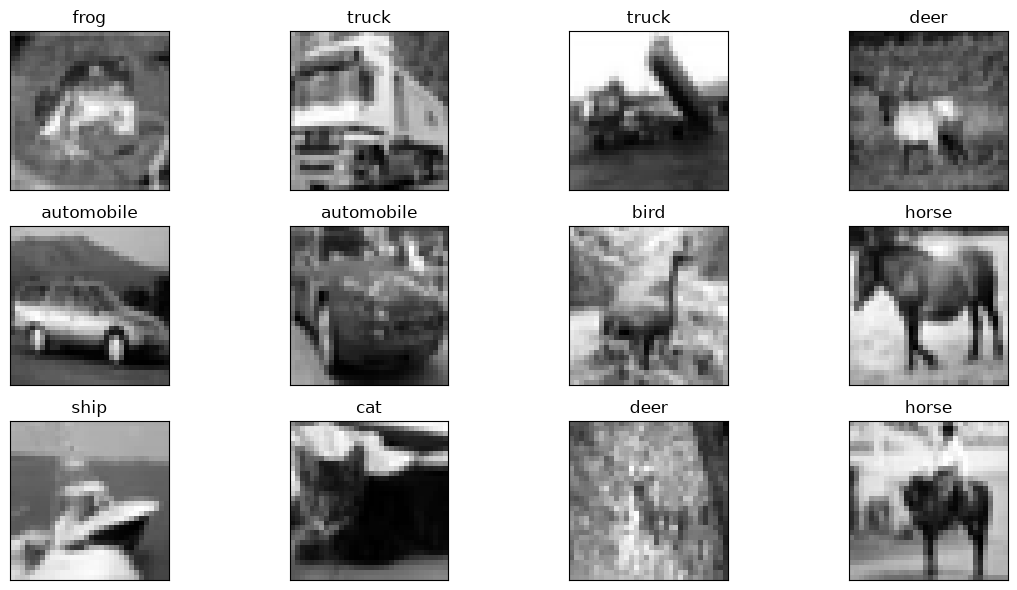

In [6]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [7]:
# TODO 2 — Completa la arquitectura
model = keras.Sequential([
    keras.Input(shape=(32, 32)),            # imagen en gris de 32x32
    layers.Flatten(),                       # 32x32 -> vector de 1024
    layers.Dense(128, activation="relu"),   # capa oculta con 128 neuronas
    layers.Dense(10)                        # 10 logits, uno por clase (sin softmax)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,490 (517.54 KB)

 Trainable params: 132,490 (517.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Validación TODO 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Una capa `Dense` recibe un **vector** de entrada (cada neurona se conecta con todos los valores). La imagen llega como una matriz `32×32`, así que `Flatten()` la convierte en un vector de 1024 valores para poder conectarla a la capa densa.


**3.** ¿Por qué la última capa tiene 10 neuronas?

**Respuesta:** Porque CIFAR-10 tiene **10 clases**. Cada neurona produce el puntaje (logit) de una clase y la predicción es la clase con el puntaje más alto.


**4.** ¿Qué función cumple `ReLU`?

**Respuesta:** `ReLU(x) = max(0, x)` agrega **no linealidad**. Sin ella, dos capas `Dense` seguidas equivalen a una sola transformación lineal y la red no podría aprender relaciones complejas. Además es barata de calcular y ayuda a que los gradientes no se hagan muy pequeños.

---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [9]:
lr_rate = 0.001

# TODO 3 — Configura el entrenamiento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),                  # optimizador Adam
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),       # etiquetas enteras + logits
    metrics=["accuracy"]
)

### Pregunta 5

¿Por qué usamos `from_logits=True`?

**Respuesta:** Porque la última capa **no tiene softmax**: entrega logits (números reales sin normalizar). Con `from_logits=True` la función de pérdida aplica internamente el softmax antes de calcular la entropía cruzada. Hacerlo así es más estable numéricamente que poner un softmax en la red y luego calcular el logaritmo.

---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [10]:
epochs = 10
batch_size = 64

# TODO 4 — Entrenamiento
history = model.fit(
    X_train,                       # imágenes de entrenamiento
    y_train,                       # etiquetas de entrenamiento
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)

Epoch 1/10


  1/782 ━━━━━━━━━━━━━━━━━━━━ 13:59 1s/step - accuracy: 0.0938 - loss: 2.4658

 22/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1186 - loss: 2.3453  

 44/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1417 - loss: 2.2842

 63/782 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1528 - loss: 2.2508

...

698/782 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3821 - loss: 1.7507

719/782 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3820 - loss: 1.7504

739/782 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3832 - loss: 1.7483

759/782 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3828 - loss: 1.7487

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3828 - loss: 1.7484 - val_accuracy: 0.3644 - val_loss: 1.7828


### Preguntas

**6.** ¿Qué representa una `epoch`?

**Respuesta:** Una época es **una pasada completa por todo el conjunto de entrenamiento** (las 50.000 imágenes). Con 10 épocas el modelo ve cada imagen 10 veces.


**7.** ¿Qué representa `batch_size=64`?

**Respuesta:** Que los parámetros se actualizan después de procesar grupos (mini-batches) de **64 imágenes**: se calcula la pérdida promedio de esas 64, se hace backpropagation y se da un paso de Adam. En una época hay $50000/64 \approx 782$ actualizaciones.

## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


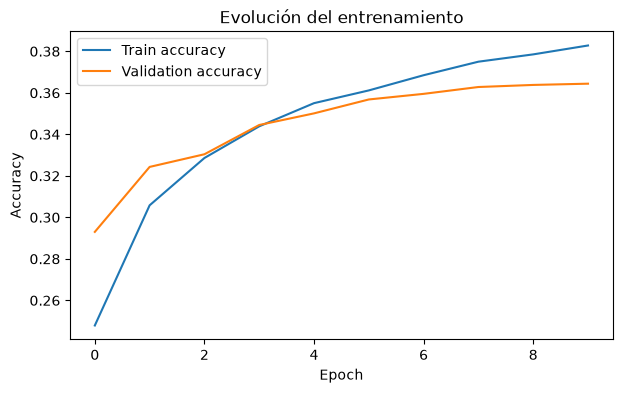

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ¿Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** No hay overfitting fuerte, el problema es más bien de **underfitting** (el modelo se queda corto). Las dos curvas suben juntas: al final el accuracy de entrenamiento es ≈ 0.38 y el de validación ≈ 0.36. La brecha es pequeña (≈ 2 puntos), aunque crece un poco en las últimas épocas, porque la validación casi se estanca mientras el entrenamiento sigue subiendo despacio. Ese sería el comienzo de un leve sobreajuste. Lo principal es que **ambos valores son bajos**: la red no tiene la capacidad adecuada para este problema.

---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [12]:
# TODO 5 — Evaluación
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")

Test loss     : 1.7828
Test accuracy : 0.3644
Accuracy (%)  : 36.44%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

¿CIFAR-10 en escala de grises parece más fácil o más difícil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** **Mucho más difícil.** Con la misma receta (Flatten → Dense(128) → ReLU → Dense(10)), en Fashion-MNIST se logra alrededor de **85–88 %** de accuracy, mientras que aquí obtuvimos solo **≈ 36.4 %** (el azar sería 10 %). Las razones:
- En Fashion-MNIST la prenda está centrada, sobre un fondo negro limpio y siempre con la misma orientación.
- En CIFAR-10 los objetos son fotos reales con fondos variados, distintos tamaños, posiciones y ángulos.
- Al pasar a escala de grises perdemos el color, que ayuda mucho (cielo azul para aviones, agua para barcos, pasto verde para ranas o venados).

---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


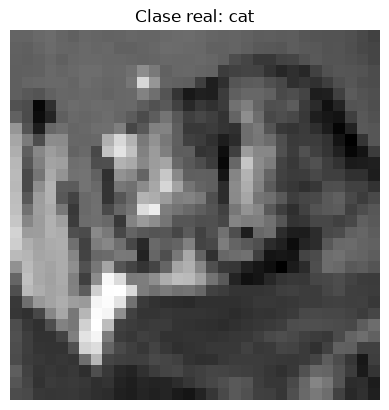

Logits:
[[ 1.0159081  -1.5197878   1.565548    0.19026011  1.2189476   0.24033228
   0.38828593  0.34409863 -0.18995267 -1.9548081 ]]


In [13]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [14]:
# TODO 6 — Logits -> probabilidades
probabilities = keras.ops.softmax(logits)

# TODO 7 — Clase con mayor probabilidad
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print("Clase real     :", class_names[true_class])
print("Clase predicha :", class_names[prediction])

Clase real     : cat
Clase predicha : bird


In [15]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.1580
automobile  : 0.0125
bird        : 0.2737 ← predicción
cat         : 0.0692
deer        : 0.1935
dog         : 0.0727
frog        : 0.0843
horse       : 0.0807
ship        : 0.0473
truck       : 0.0081

Suma: 1.0000001


### Pregunta 10

¿Por qué las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Softmax calcula $p_i = e^{z_i} / \sum_j e^{z_j}$. Cada término se divide por la suma de todos, así que el total da exactamente 1 (sale "aproximadamente" 1 solo por el redondeo de los números en punto flotante). Así las salidas forman una **distribución de probabilidad** sobre las 10 clases: la imagen tiene que pertenecer a alguna de ellas.

---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


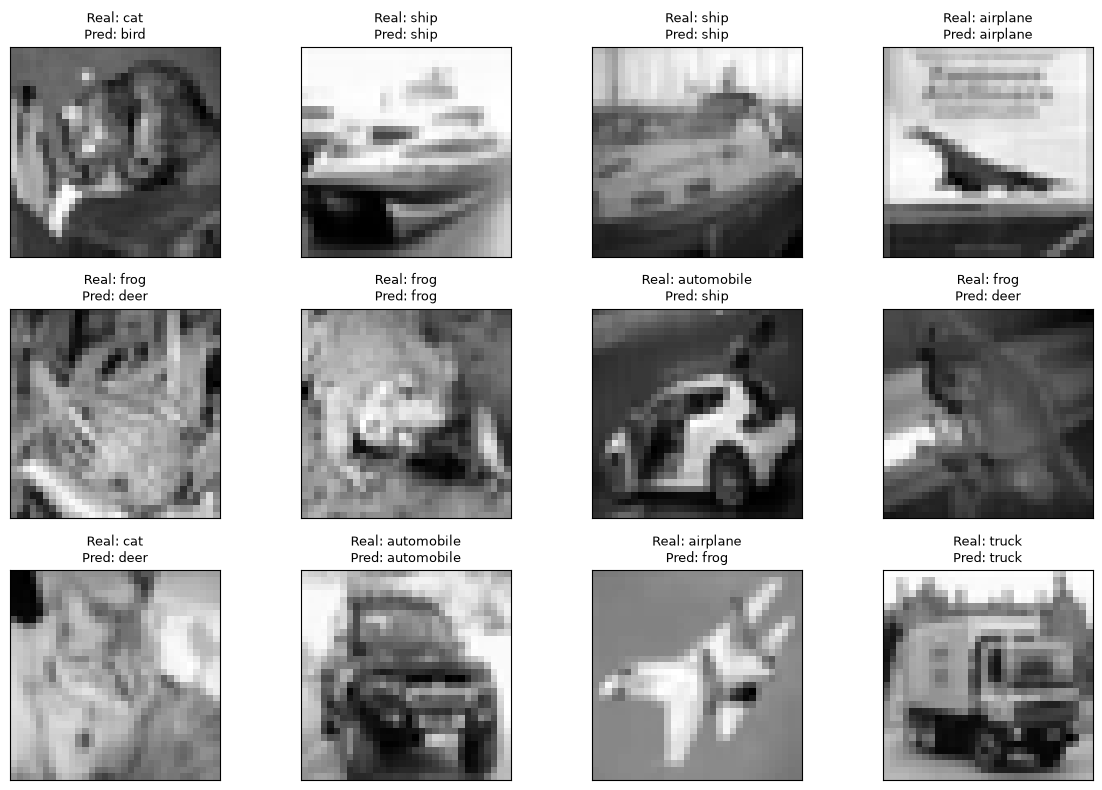

In [16]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


### Accuracy por clase

Para responder qué clases son más difíciles, calculamos el porcentaje de aciertos de cada clase en todo el conjunto de prueba.

In [17]:
# Predicciones para las 10.000 imágenes de prueba
logits_test = model.predict(X_test, batch_size=256, verbose=0)
pred_test = np.argmax(logits_test, axis=1)

# Accuracy de cada clase = aciertos de esa clase / total de esa clase
print("Accuracy por clase (de mayor a menor):")
acc_por_clase = []
for i, nombre in enumerate(class_names):
    mascara = (y_test == i)
    acc_por_clase.append((nombre, np.mean(pred_test[mascara] == i)))

for nombre, acc in sorted(acc_por_clase, key=lambda t: t[1], reverse=True):
    print(f"{nombre:12s}: {acc:.2%}")

# ¿Con qué clase se confunde más cada una?
print("\nConfusión más frecuente de cada clase:")
for i, nombre in enumerate(class_names):
    errores = pred_test[(y_test == i) & (pred_test != i)]
    mas_comun = np.bincount(errores, minlength=10).argmax()
    print(f"{nombre:12s} -> {class_names[mas_comun]}")

Accuracy por clase (de mayor a menor):
ship        : 57.60%
airplane    : 41.60%
automobile  : 40.90%
horse       : 39.20%
truck       : 39.20%
deer        : 37.70%
bird        : 31.30%
dog         : 29.80%
frog        : 27.70%
cat         : 19.40%

Confusión más frecuente de cada clase:
airplane     -> ship
automobile   -> ship
bird         -> deer
cat          -> dog
deer         -> airplane
dog          -> cat
frog         -> deer
horse        -> airplane
ship         -> airplane
truck        -> automobile


---
# 8. Reflexión final

### 1. ¿Cuál fue el accuracy final?

**Respuesta:** **≈ 0.3644 (36.44 %)** en el conjunto de prueba, con test loss ≈ 1.78. Es bastante mejor que el azar (10 %) pero un resultado bajo.


### 2. ¿Qué clases parecen más difíciles de distinguir?

**Respuesta:** Según el accuracy por clase, las más difíciles son **cat (≈ 19 %)**, **frog (≈ 28 %)**, **dog (≈ 30 %)** y **bird (≈ 31 %)**: los animales. Además **gato y perro se confunden entre sí** (el error más común del gato es "dog" y el del perro es "cat"), y bird/frog se confunden con deer. También se confunden **airplane ↔ ship** (fondos lisos de cielo o agua que en gris se parecen) y **truck → automobile**. La más fácil fue **ship (≈ 58 %)**.


### 3. Después de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ¿Qué información importante sobre la imagen podría perderse al tratarla únicamente como un vector?

**Respuesta:** Se pierde la **estructura espacial**: qué píxeles son vecinos. La red ya no "sabe" que un píxel está al lado de otro, así que no aprovecha patrones locales como bordes, esquinas, texturas o formas. Tampoco tiene invariancia a la posición: si el gato aparece a la izquierda o a la derecha, para la red son vectores totalmente distintos y tiene que aprender cada caso por separado.


### 4. ¿Qué tipo de arquitectura podría aprovechar mejor la estructura espacial de las imágenes?

**Respuesta:** Las **redes neuronales convolucionales (CNNs)**. Usan filtros pequeños (por ejemplo 3×3) que recorren la imagen para detectar bordes y texturas, y luego combinan esos patrones en formas más complejas. Como comparten los pesos del filtro en toda la imagen, necesitan menos parámetros y reconocen el objeto aunque cambie de posición. En CIFAR-10 una CNN sencilla supera fácilmente el 60–70 %.

---

## Para pensar

Nuestro modelo hace:

```text
32×32 → Flatten → 1024 valores → Dense → ReLU → Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **¿Cómo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta será: **Convolutional Neural Networks (CNNs)**.